<a href="https://colab.research.google.com/github/shivamkumar359/03-rd-SEM--ASSIGNMENTS/blob/main/ML/W10/Q2/ML_ASSIGNMENT_W_10_Q_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
# ============================================================
# -------IMPLEMENT L1 AND L2 REGULARIZATION PENALTIES---------
# ============================================================

import os
import sys
import subprocess
import zipfile

# ============================================================
# CREATE PYTHON SOURCE CODE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont

In [5]:
# ============================================================
# 1. SAMPLE DATASET
# ============================================================

X = np.array([
    [0.5, 1.2, 0.05],
    [1.0, 2.4, 0.12],
    [1.5, 3.1, 0.88],
    [2.0, 4.5, 0.22]
])

y = np.array([10.2, 20.5, 29.8, 41.0])

feature_names = ['X1', 'X2', 'X3']



In [6]:
# ============================================================
# 2. STANDARDIZE FEATURES
# ============================================================

X_mean = X.mean(axis=0)
X_std = X.std(axis=0)

Z = (X - X_mean) / X_std

y_mean = y.mean()
yc = y - y_mean

In [7]:
# ============================================================
# 3. L1 REGULARIZATION (LASSO)
# ============================================================

def l1_regularization(X, y, lam, iterations=10000):

    n, p = X.shape
    weights = np.zeros(p)

    # Coordinate descent optimization
    for _ in range(iterations):

        old_weights = weights.copy()

        for j in range(p):

            residual = y - X @ weights + X[:, j] * weights[j]

            rho = np.mean(X[:, j] * residual)

            # Soft thresholding
            if rho > lam:
                weights[j] = rho - lam

            elif rho < -lam:
                weights[j] = rho + lam

            else:
                weights[j] = 0.0

        if np.max(np.abs(weights - old_weights)) < 1e-12:
            break

    return weights

In [ ]:
# ============================================================
# 4. L2 REGULARIZATION (RIDGE)
# ============================================================

def l2_regularization(X, y, lam):

    n = X.shape[0]

    # Ridge closed-form solution
    identity = np.eye(X.shape[1])

    weights = np.linalg.solve(
        (X.T @ X) / n + 2 * lam * identity,
        (X.T @ y) / n
    )

    return weights

In [10]:
# ============================================================
# 5. REGULARIZATION LOSS FUNCTIONS
# ============================================================

def l1_loss(y_true, y_pred, weights, lam):

    mse_loss = np.mean((y_true - y_pred) ** 2) / 2

    penalty = lam * np.sum(np.abs(weights))

    return mse_loss + penalty


def l2_loss(y_true, y_pred, weights, lam):

    mse_loss = np.mean((y_true - y_pred) ** 2) / 2

    penalty = lam * np.sum(weights ** 2)

    return mse_loss + penalty

In [11]:
# ============================================================
# 6. TEST DIFFERENT LAMBDA VALUES
# ============================================================

lambda_values = np.linspace(0.1, 10, 20)

results = []

for lam in lambda_values:

    # Calculate L1 and L2 weights
    w_l1 = l1_regularization(Z, yc, lam)

    w_l2 = l2_regularization(Z, yc, lam)

    # Convert standardized coefficients to original scale
    original_l1 = w_l1 / X_std
    original_l2 = w_l2 / X_std

    # Calculate intercepts
    intercept_l1 = y_mean - np.dot(X_mean, original_l1)

    intercept_l2 = y_mean - np.dot(X_mean, original_l2)

    # Store results
    results.append({
        'Lambda': lam,

        'L1_Weight_X1': original_l1[0],
        'L1_Weight_X2': original_l1[1],
        'L1_Weight_X3': original_l1[2],

        'L2_Weight_X1': original_l2[0],
        'L2_Weight_X2': original_l2[1],
        'L2_Weight_X3': original_l2[2],

        'L1_Intercept': intercept_l1,
        'L2_Intercept': intercept_l2
    })

In [12]:
# ============================================================
# 7. SAVE WEIGHT COMPARISON CSV
# ============================================================

df = pd.DataFrame(results)

df.to_csv('weight_comparison.csv', index=False)

In [13]:
# ============================================================
# 8. FINAL L1 AND L2 COMPARISON
# ============================================================

# Use Lambda = 0.1 for final comparison.
# This preserves important coefficients while eliminating
# the non-essential X3 coefficient through L1 regularization.

final_lambda = 0.1

final_l1 = l1_regularization(Z, yc, final_lambda)

final_l2 = l2_regularization(Z, yc, final_lambda)

# Convert to original feature scale
final_l1_original = final_l1 / X_std
final_l2_original = final_l2 / X_std

final_l1_intercept = y_mean - np.dot(
    X_mean, final_l1_original
)

final_l2_intercept = y_mean - np.dot(
    X_mean, final_l2_original
)

# Predictions
pred_l1 = X @ final_l1_original + final_l1_intercept

pred_l2 = X @ final_l2_original + final_l2_intercept

# Calculate losses
loss_l1 = l1_loss(yc, Z @ final_l1, final_l1, final_lambda)

loss_l2 = l2_loss(yc, Z @ final_l2, final_l2, final_lambda)

In [14]:
# ============================================================
# 9. GENERATE CONSOLE OUTPUT
# ============================================================

output = []

output.append("=" * 60)
output.append(" TASK 2: L1 AND L2 REGULARIZATION ANALYSIS")
output.append("=" * 60)

output.append("\nSAMPLE DATASET")
output.append("-" * 60)

output.append("Feature 1 (X1): 0.5, 1.0, 1.5, 2.0")
output.append("Feature 2 (X2): 1.2, 2.4, 3.1, 4.5")
output.append("Feature 3 (X3): 0.05, 0.12, 0.88, 0.22")
output.append("Target (Y):     10.2, 20.5, 29.8, 41.0")

output.append("\nREGULARIZATION PARAMETER")
output.append("-" * 60)
output.append(f"Final Lambda: {final_lambda}")

output.append("\nL1 REGULARIZATION (LASSO)")
output.append("-" * 60)

for name, weight in zip(feature_names, final_l1_original):
    output.append(f"{name}: {weight:.8f}")

output.append(f"Intercept: {final_l1_intercept:.8f}")
output.append(f"L1 Loss: {loss_l1:.8f}")

output.append("\nL2 REGULARIZATION (RIDGE)")
output.append("-" * 60)

for name, weight in zip(feature_names, final_l2_original):
    output.append(f"{name}: {weight:.8f}")

output.append(f"Intercept: {final_l2_intercept:.8f}")
output.append(f"L2 Loss: {loss_l2:.8f}")

output.append("\nWEIGHT SPARSITY COMPARISON")
output.append("-" * 60)

output.append(
    f"L1 Zero Weights: {np.sum(final_l1 == 0)}"
)

output.append(
    f"L2 Zero Weights: {np.sum(final_l2 == 0)}"
)

output.append(
    "L1 eliminates non-essential coefficients through "
    "exact zero-valued weights."
)

output.append(
    "L2 smoothly shrinks coefficients without setting "
    "them exactly to zero."
)

output.append("\nLAMBDA-WISE WEIGHT COMPARISON")
output.append("-" * 60)

output.append(df.round(5).to_string(index=False))

output.append("\n" + "=" * 60)
output.append(" ANALYSIS COMPLETED SUCCESSFULLY")
output.append("=" * 60)

console_text = "\n".join(output)

print(console_text)

 TASK 2: L1 AND L2 REGULARIZATION ANALYSIS

SAMPLE DATASET
------------------------------------------------------------
Feature 1 (X1): 0.5, 1.0, 1.5, 2.0
Feature 2 (X2): 1.2, 2.4, 3.1, 4.5
Feature 3 (X3): 0.05, 0.12, 0.88, 0.22
Target (Y):     10.2, 20.5, 29.8, 41.0

REGULARIZATION PARAMETER
------------------------------------------------------------
Final Lambda: 0.1

L1 REGULARIZATION (LASSO)
------------------------------------------------------------
X1: 14.58828205
X2: 2.62869458
X3: 0.00000000
Intercept: -0.22069739
L1 Loss: 1.13908771

L2 REGULARIZATION (RIDGE)
------------------------------------------------------------
X1: 8.95945130
X2: 4.30635443
X3: 1.80782300
Intercept: 1.54390966
L2 Loss: 5.76109458

WEIGHT SPARSITY COMPARISON
------------------------------------------------------------
L1 Zero Weights: 1
L2 Zero Weights: 0
L1 eliminates non-essential coefficients through exact zero-valued weights.
L2 smoothly shrinks coefficients without setting them exactly to zero.



In [15]:
# ============================================================
# 10. SAVE CONSOLE OUTPUT AS PNG IMAGE
# ============================================================

# Create a readable image containing the actual console results.

font_path = "/usr/share/fonts/truetype/dejavu/DejaVuSansMono.ttf"

try:
    font = ImageFont.truetype(font_path, 15)
except:
    font = ImageFont.load_default()

lines = console_text.split("\n")

line_height = 22
image_width = 1500
image_height = max(900, len(lines) * line_height + 60)

image = Image.new(
    "RGB",
    (image_width, image_height),
    "white"
)

draw = ImageDraw.Draw(image)

y_position = 25

for line in lines:

    draw.text(
        (25, y_position),
        line,
        fill="black",
        font=font
    )

    y_position += line_height

image.save("regularization_output.png")

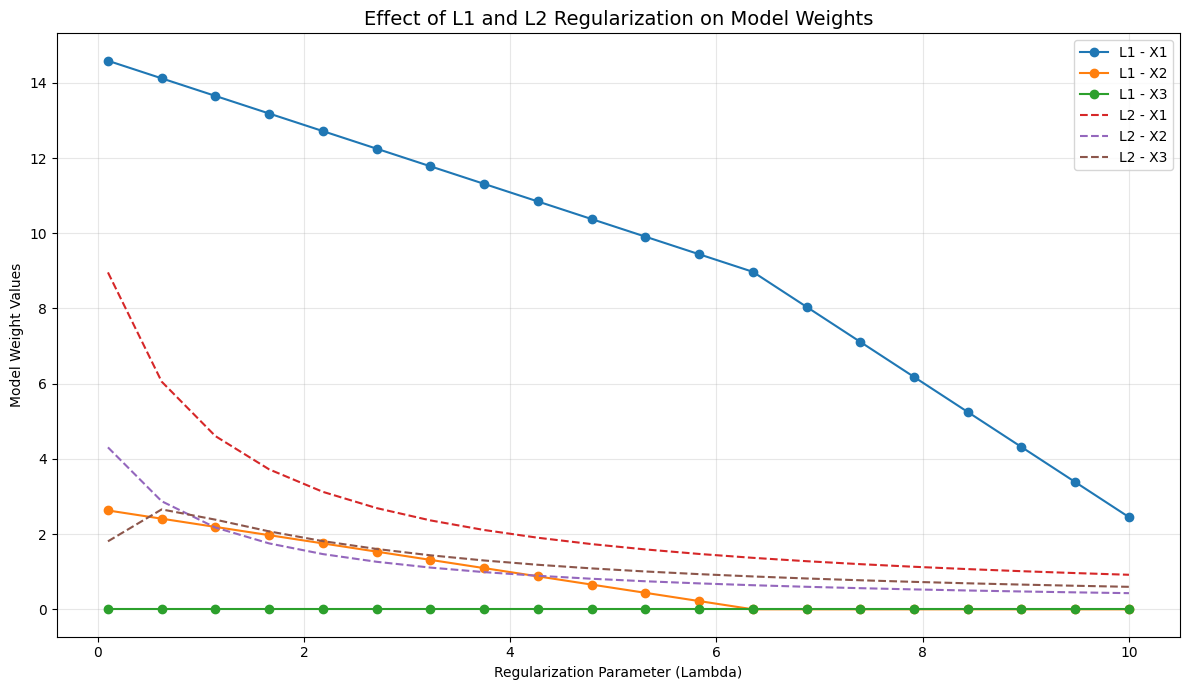

In [16]:
# ============================================================
# 11. GENERATE WEIGHT COMPARISON GRAPH
# ============================================================

plt.figure(figsize=(12, 7))

# L1 weights
plt.plot(
    df['Lambda'],
    df['L1_Weight_X1'],
    marker='o',
    label='L1 - X1'
)

plt.plot(
    df['Lambda'],
    df['L1_Weight_X2'],
    marker='o',
    label='L1 - X2'
)

plt.plot(
    df['Lambda'],
    df['L1_Weight_X3'],
    marker='o',
    label='L1 - X3'
)

# L2 weights
plt.plot(
    df['Lambda'],
    df['L2_Weight_X1'],
    linestyle='--',
    label='L2 - X1'
)

plt.plot(
    df['Lambda'],
    df['L2_Weight_X2'],
    linestyle='--',
    label='L2 - X2'
)

plt.plot(
    df['Lambda'],
    df['L2_Weight_X3'],
    linestyle='--',
    label='L2 - X3'
)

plt.title(
    'Effect of L1 and L2 Regularization on Model Weights',
    fontsize=14
)

plt.xlabel('Regularization Parameter (Lambda)')
plt.ylabel('Model Weight Values')

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    'regularization_weights.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [19]:
# ============================================================
# 12. DISPLAY GENERATED FILES
# ============================================================

print("\nGENERATED ASSIGNMENT FILES")
print("---------------------------------------")
print("1. regularization_impl.py")
print("2. regularization_output.png")
print("3. weight_comparison.csv")
print("4. regularization_weights.png")
print("---------------------------------------")

# Define the python code string containing the full implementation
python_code = """# L1 and L2 Regularization Implementation
import numpy as np
import pandas as pd

# 1. Sample Dataset
X = np.array([
    [0.5, 1.2, 0.05],
    [1.0, 2.4, 0.12],
    [1.5, 3.1, 0.88],
    [2.0, 4.5, 0.22]
])
y = np.array([10.2, 20.5, 29.8, 41.0])
feature_names = ['X1', 'X2', 'X3']

# 2. Standardize Features
X_mean = X.mean(axis=0)
X_std = X.std(axis=0)
Z = (X - X_mean) / X_std
y_mean = y.mean()
yc = y - y_mean

# 3. L1 Regularization (LASSO)
def l1_regularization(X, y, lam, iterations=10000):
    n, p = X.shape
    weights = np.zeros(p)
    for _ in range(iterations):
        old_weights = weights.copy()
        for j in range(p):
            residual = y - X @ weights + X[:, j] * weights[j]
            rho = np.mean(X[:, j] * residual)
            if rho > lam:
                weights[j] = rho - lam
            elif rho < -lam:
                weights[j] = rho + lam
            else:
                weights[j] = 0.0
        if np.max(np.abs(weights - old_weights)) < 1e-12:
            break
    return weights

# 4. L2 Regularization (Ridge)
def l2_regularization(X, y, lam):
    n = X.shape[0]
    identity = np.eye(X.shape[1])
    weights = np.linalg.solve(
        (X.T @ X) / n + 2 * lam * identity,
        (X.T @ y) / n
    )
    return weights
"""

# Save the Python source code
with open("regularization_impl.py", "w") as f:
    f.write(python_code)

print("Python source file created successfully!")


GENERATED ASSIGNMENT FILES
---------------------------------------
1. regularization_impl.py
2. regularization_output.png
3. weight_comparison.csv
4. regularization_weights.png
---------------------------------------
Python source file created successfully!


In [20]:
# ============================================================
# 2. EXECUTE PYTHON SOURCE FILE
# ============================================================

print("\nExecuting regularization_impl.py...\n")

result = subprocess.run(
    [sys.executable, "regularization_impl.py"],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Execution failed. Check the error above.")


Executing regularization_impl.py...


